In [ ]:
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelBinarizer, MultiLabelBinarizer

# Define a toy dataset of apartment rental prices in
# New York, San Francisco, and Seattle
df = pd.DataFrame({'City': ['SF', 'SF', 'SF', 'NYC', 'NYC', 'NYC', 'Seattle', 'Seattle', 'Seattle'],
                   'Rent': [3999, 4000, 4001, 3499, 3500, 3501, 2499, 2500, 2501]})
print("Média dos alugueis: ", df['Rent'].mean())

# extraindo One-hot com sklearln:
one_hot = LabelBinarizer()
one_hot_vectors = one_hot.fit_transform(df['City'])
print(one_hot.classes_)
print (one_hot_vectors)

# ou com pandas:
print ('########## ONE-HOT ENCONDING ##########')
# Convert the categorical variables in the DataFrame to one-hot encoding
one_hot_df = pd.get_dummies(df, prefix=['city'], dtype=int)
one_hot_df


Média dos alugueis:  3333.3333333333335
['NYC' 'SF' 'Seattle']
[[0 1 0]
 [0 1 0]
 [0 1 0]
 [1 0 0]
 [1 0 0]
 [1 0 0]
 [0 0 1]
 [0 0 1]
 [0 0 1]]
########## ONE-HOT ENCONDING ##########


,Rent,city_NYC,city_SF,city_Seattle
0,3999,0,1,0
1,4000,0,1,0
2,4001,0,1,0
3,3499,1,0,0
4,3500,1,0,0
5,3501,1,0,0
6,2499,0,0,1
7,2500,0,0,1
8,2501,0,0,1


In [ ]:
# Specify the 'drop_first' flag to get dummy coding
print ('########## DUMMY ENCONDING ##########')

dummy_df = pd.get_dummies(df, prefix=['city'], drop_first=True, dtype=int)
dummy_df

# (False, False) means city=NYC

########## DUMMY ENCONDING ##########


,Rent,city_SF,city_Seattle
0,3999,1,0
1,4000,1,0
2,4001,1,0
3,3499,0,0
4,3500,0,0
5,3501,0,0
6,2499,0,1
7,2500,0,1
8,2501,0,1


In [ ]:
print ('########## EFFECT ENCONDING ##########')

effect_df = dummy_df.copy()
mask = (effect_df['city_SF'] == 0) & (effect_df['city_Seattle'] == 0)
effect_df.loc[mask, ['city_SF', 'city_Seattle']] = -1
effect_df


########## EFFECT ENCONDING ##########


,Rent,city_SF,city_Seattle
0,3999,1,0
1,4000,1,0
2,4001,1,0
3,3499,-1,-1
4,3500,-1,-1
5,3501,-1,-1
6,2499,0,1
7,2500,0,1
8,2501,0,1


In [ ]:
# and fit a linear regression model
model = LinearRegression()
model.fit(one_hot_df[['city_NYC', 'city_SF', 'city_Seattle']],
          one_hot_df['Rent'])
print(model.coef_)
print(model.intercept_)

[ 166.66666667  666.66666667 -833.33333333]
3333.3333333333335


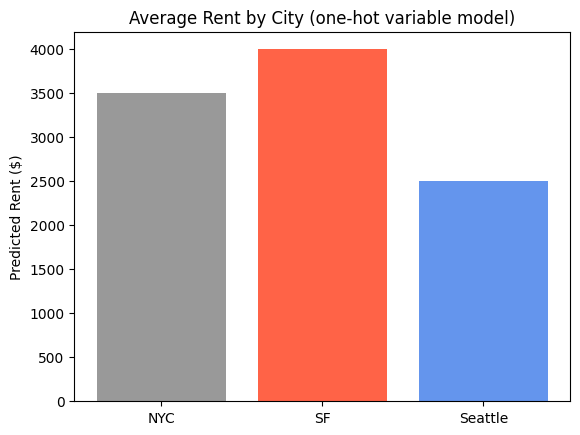

In [ ]:
plt.bar(['NYC', 'SF', 'Seattle'],
        [model.intercept_ + model.coef_[0],
         model.intercept_ + model.coef_[1],
         model.intercept_ + model.coef_[2]],
        color=['#999', 'tomato', 'cornflowerblue'])

plt.ylabel('Predicted Rent ($)')
plt.title('Average Rent by City (one-hot variable model)')
plt.show()

In [ ]:
# Train a linear regression model on dummy code
model.fit(dummy_df[['city_SF', 'city_Seattle']], dummy_df['Rent'])
print(model.coef_)
print(model.intercept_)

[  500. -1000.]
3500.0


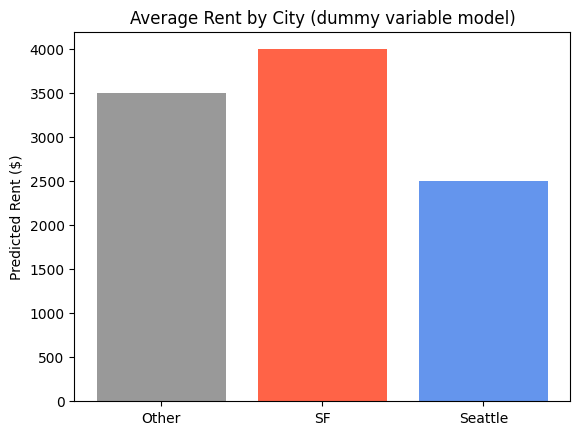

In [ ]:
plt.bar(['Other', 'SF', 'Seattle'],
        [model.intercept_,
         model.intercept_ + model.coef_[0],
         model.intercept_ + model.coef_[1]],
        color=['#999', 'tomato', 'cornflowerblue'])

plt.ylabel('Predicted Rent ($)')
plt.title('Average Rent by City (dummy variable model)')
plt.show()

In [ ]:
# linear regression
model.fit(effect_df[['city_SF', 'city_Seattle']], effect_df['Rent'])
print(model.coef_)
print(model.intercept_)

[ 666.66666667 -833.33333333]
3333.3333333333335


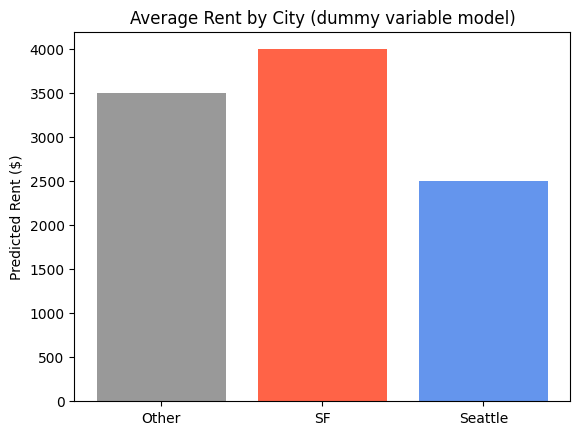

In [ ]:
plt.bar(['Other', 'SF', 'Seattle'],
        [model.intercept_ - model.coef_[0] - model.coef_[1],
         model.intercept_ + model.coef_[0],
         model.intercept_ + model.coef_[1]],
        color=['#999', 'tomato', 'cornflowerblue'])

plt.ylabel('Predicted Rent ($)')
plt.title('Average Rent by City (dummy variable model)')
plt.show()